In [7]:
import pandas as pd
import numpy as np
from scipy.stats import lognorm
from scipy.optimize import curve_fit
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm, LinearSegmentedColormap
from matplotlib.gridspec import GridSpec
from matplotlib.patches import Ellipse
from mpl_toolkits.axes_grid1.inset_locator import inset_axes, mark_inset

# **Visualising Duplicates**

In [8]:
h23 = pd.read_csv("../1_inputdata_clean/hatt23_asteroseismic.csv")
s26 = pd.read_csv("../1_inputdata_clean/sree26_asteroseismic.csv")
w26 = pd.read_csv("../1_inputdata_clean/will26_asteroseismic.csv")
y18 = pd.read_csv("../1_inputdata_clean/yu18_asteroseismic.csv")
z22 = pd.read_csv("../1_inputdata_clean/zinn22_asteroseismic.csv")

full_data = pd.concat([h23, s26, w26, y18, z22], ignore_index=True)
full_data.to_csv("./asteroseismic_full.csv", index=False)

In [9]:
dup_ids = full_data.loc[full_data["gaiadr3_id"].duplicated(keep=False), "gaiadr3_id"].unique().tolist()

dup_distances = []

for id in dup_ids:
    subset = full_data.loc[full_data["gaiadr3_id"] == id]

    numax_vals = subset["numax"].dropna().to_numpy()
    dnu_vals = subset["dnu"].dropna().to_numpy()

    # mean difference of every distinct pair in duplicates
    if len(numax_vals) > 1:
        i, j = np.triu_indices(len(numax_vals), k=1)
        mean_numax_diff = np.mean(np.abs(numax_vals[i] - numax_vals[j]))
    else:
        mean_numax_diff = np.nan

    if len(dnu_vals) > 1:
        i, j = np.triu_indices(len(dnu_vals), k=1)
        mean_dnu_diff = np.mean(np.abs(dnu_vals[i] - dnu_vals[j]))
    else:
        mean_dnu_diff = np.nan

    dup_distances.append({
        "gaiadr3_id": id,
        "numax_diff": mean_numax_diff,
        "dnu_diff": mean_dnu_diff
    })

dup_distances = pd.DataFrame(dup_distances).dropna()

Plot 2D histogram distribution of these mean distances.

Note: given log-normal distribution, we find the original std using $e^{\mu + (\sigma^2_\mathrm{log}/2)}\sqrt{e^{\sigma_\mathrm{log}^2} - 1}$.

In [10]:
# log-normal model function
def lognormal_dist(x, amplitude, shape, scale):
    return amplitude * lognorm.pdf(x, s=shape, loc=0, scale=scale)

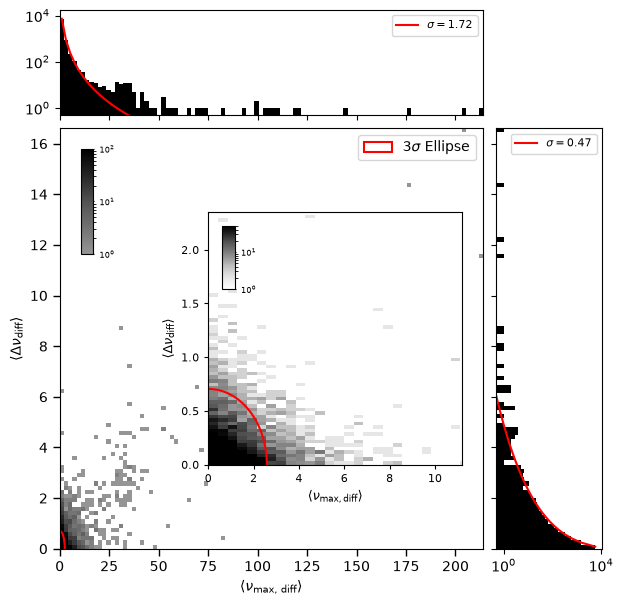

In [11]:
# def x and y axes for plotting
x = dup_distances["numax_diff"]
y = dup_distances["dnu_diff"]

# darker cmap
cmap = plt.colormaps["Greys"].resampled(256)
cmap = LinearSegmentedColormap.from_list(
    "Greys_DARK", cmap(np.linspace(0.5, 1, 256))
)

fig = plt.figure(figsize=(7, 7))
gs = GridSpec(2, 2, width_ratios=[4, 1], height_ratios=[1, 4],
              hspace=0.05, wspace=0.05)

ax_top = fig.add_subplot(gs[0, 0])
ax_main = fig.add_subplot(gs[1, 0], sharex=ax_top)
ax_right = fig.add_subplot(gs[1, 1], sharey=ax_main)

hist, xedges, yedges = np.histogram2d(x, y, bins=100) # full histogram
zoomhist, zoomxedges, zoomyedges = np.histogram2d(x, y, bins=500) # zoom-in histogram

# main plot
ax_main.imshow(hist.T, origin="lower", extent=[xedges[0], xedges[-1], yedges[0], yedges[-1]],
               aspect="auto", cmap=cmap, norm=LogNorm(vmin=1, vmax=100))
ax_main.set_xlabel(r"$\langle\nu_\mathrm{max,\,diff}\rangle$")
ax_main.set_ylabel(r"$\langle\Delta\nu_\mathrm{diff}\rangle$")
ax_main.set_xlim(0, None)
ax_main.set_ylim(0, None)
ax_main.tick_params(axis="both", labelsize=10)
ax_main.tick_params(axis="both", length=5, width=1)

# top plot - numax histogram
counts, bins, _ = ax_top.hist(x, bins=xedges, color="black")
x_pos = (bins[1:] + bins[:-1]) / 2 # bins centres for hist
initials = [counts.max(), 1.0, np.median(x)] # initial inputs for amp, shape, scale
res, _ = curve_fit(lognormal_dist, x_pos, counts, p0=initials, maxfev=20000) # fit log-normal to histogram
_, log_sigma, scale = res
mean_fit = scale * np.exp(log_sigma**2 / 2)
x_std_fit = mean_fit * np.sqrt(np.exp(log_sigma**2) - 1)
ax_top.plot(x_pos, lognormal_dist(x_pos, *res), # unpack amp, shape, scale from res
            color="red", lw=1.5, label=rf"$\sigma = {x_std_fit:.2f}$")
ax_top.legend(loc="upper right", fontsize=8)

# right plot - dnu histogram
counts, bins, _ = ax_right.hist(y, bins=yedges, orientation="horizontal", color="black")
y_pos = (bins[1:] + bins[:-1]) / 2 # bins centres for hist
initials = [counts.max(), 1.0, np.median(y)] # initial inputs for amp, shape, scale
res, _ = curve_fit(lognormal_dist, y_pos, counts, p0=initials, maxfev=20000) # fit log-normal to histogram
_, log_sigma, scale = res
mean_fit = scale * np.exp(log_sigma**2 / 2)
y_std_fit = mean_fit * np.sqrt(np.exp(log_sigma**2) - 1)
ax_right.plot(lognormal_dist(y_pos, *res), y_pos, # unpack amp, shape, scale from res
              color="red", lw=1.5, label=rf"$\sigma = {y_std_fit:.2f}$")
ax_right.legend(loc="upper right", fontsize=8)

# outer plots settings
ax_top.tick_params(axis="x", labelbottom=False, labelsize=8)
ax_top.set_yscale("log")
ax_top.set_ylim(5e-1, None)
ax_right.tick_params(axis="y", labelleft=False, labelsize=8)
ax_right.set_xscale("log")
ax_right.set_xlim(5e-1, None)

# oval overplot
oval = Ellipse(xy=(0, 0), width=3*x_std_fit, height=3*y_std_fit, angle=0, 
               edgecolor="red", facecolor="none", linewidth=1.5, label=r"$3\sigma$ Ellipse")
ax_main.add_patch(oval)
ax_main.legend(loc="upper right", fontsize=10)

# zoom-in plot
ax_zoom = inset_axes(ax_main, width="60%", height="60%", loc="center right", borderpad=1.5)
ax_zoom.imshow(zoomhist.T, origin="lower", extent=[zoomxedges[0], zoomxedges[-1], zoomyedges[0], zoomyedges[-1]], 
               aspect="auto", cmap="Greys", norm=LogNorm(vmin=1, vmax=50))
zoomoval = Ellipse(xy=(0, 0), width=3*x_std_fit, height=3*y_std_fit, angle=0, 
               edgecolor="red", facecolor="none", linewidth=1.5, label=r"$3\sigma$ Ellipse")
ax_zoom.add_patch(zoomoval)
ax_zoom.set_xlim(0, 6.5*x_std_fit)
ax_zoom.set_ylim(0, 5*y_std_fit)
ax_zoom.set_xlabel(r"$\langle\nu_{\mathrm{max,diff}}\rangle$", fontsize=9)
ax_zoom.set_ylabel(r"$\langle\Delta\nu_{\mathrm{diff}}\rangle$", fontsize=9)
ax_zoom.tick_params(axis="both", labelsize=8)
ax_zoom.tick_params(axis="both", length=3, width=0.8)

# cbar - main
cax_main = inset_axes(ax_main, width="3%", height="25%", loc="upper left", borderpad=1.5)
im_main = ax_main.images[0]
cbar_main = fig.colorbar(im_main, cax=cax_main)
cbar_main.ax.tick_params(labelsize=6, colors="black", length=1)
cbar_main.outline.set_edgecolor("black")

# cbar - zoom
cax_zoom = inset_axes(ax_zoom, width="5%", height="25%", loc="upper left", borderpad=1)
im_zoom = ax_zoom.images[0]
cbar_zoom = fig.colorbar(im_zoom, cax=cax_zoom)
cbar_zoom.ax.tick_params(labelsize=6, colors="black", length=1)
cbar_zoom.outline.set_edgecolor("black")

# save plot
plt.savefig("../figures/duplicates_distribution.png", dpi=300, bbox_inches="tight")

plt.show()

Write IDs within ellipse to `.csv` file.

In [12]:
within_ellipse = dup_distances[(dup_distances["numax_diff"] < 3*x_std_fit) & (dup_distances["dnu_diff"] < 3*y_std_fit)]
good_ids = within_ellipse["gaiadr3_id"].unique()
bad_ids = dup_distances.loc[
    ~dup_distances["gaiadr3_id"].isin(good_ids),
    "gaiadr3_id"
].unique()

bad_ids = pd.DataFrame({
    "bad_ids": bad_ids
})

bad_ids.to_csv("./bad_ids.csv", index=False)

good_ids = pd.DataFrame({
    "good_ids": good_ids
})

good_ids.to_csv("./good_ids.csv", index=False)